# Évolution de la courbe des taux

Objectif : est de matérialiser et visualiser l'évolution des taux. On fera alors une visualisation pour comprendre l'évolution des taux selon les différentes maturités(1 an, 2 ans, 3 ans etc....) et comprendre les causes des différentes fluctuations.

**Sources**

| Jeu | Contenu | Période |
|---|---|---|
| ECB `YC` | courbe zéro-coupon zone euro, émetteurs souverains AAA | depuis sept. 2004 |
| ECB `IRS` | taux long français 10 ans (critère de Maastricht) | depuis 1980 |

La courbe AAA zone euro sert de base à la courbe sans risque EIOPA : c'est donc la
référence pertinente pour un travail ALM. 

In [12]:
import io
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import requests

api = "https://data-api.ecb.europa.eu/service/data"
dossier = Path("donnees")
dossier.mkdir(exist_ok=True)

mat = [1, 2, 3, 5, 7, 10, 15, 20, 30]

plt.rcParams.update({
    "figure.figsize": (13, 6.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## Téléchargement des données

In [13]:
def charger_serie(cle: str, nom_fichier: str, debut: str = "2000-01-01") -> pd.Series:
    """Récupère une série de l'ECB Data Portal, avec cache local."""
    fichier = dossier/ f"{nom_fichier}.csv"
    url = f"{api}/{cle}"
    rep = requests.get(url, params={"format": "csvdata", "startPeriod": debut}, timeout=60)
    rep.raise_for_status()
    brut = pd.read_csv(io.StringIO(rep.text))
    brut.to_csv(fichier, index=False)

    s = brut.set_index(pd.to_datetime(brut["TIME_PERIOD"]))["OBS_VALUE"]
    s.index.name = "date"
    return s.sort_index()


#  Courbe zéro-coupon zone euro AAA avecune série par maturité 
colonnes = {}
for m in mat:
    cle = f"YC/B.U2.EUR.4F.G_N_A.SV_C_YM.SR_{m}Y"
    colonnes[m] = charger_serie(cle, f"yc_{m}a")
    print(f"  {m:>2} ans  ok")


courbe = pd.DataFrame(colonnes).sort_index()
print(f"\n{courbe.shape[0]:,} dates, {courbe.shape[1]} maturités")
print(f"du {courbe.index.min():%d/%m/%Y} au {courbe.index.max():%d/%m/%Y}")
courbe.tail(3)

   1 ans  ok
   2 ans  ok
   3 ans  ok
   5 ans  ok
   7 ans  ok
  10 ans  ok
  15 ans  ok
  20 ans  ok
  30 ans  ok

5,621 dates, 9 maturités
du 06/09/2004 au 01/09/2026


,1,2,3,5,7,10,15,20,30
date,,,,,,,,,
2026-08-28,2.683980,2.805378,2.850621,2.943170,3.073349,3.278920,3.542236,3.687214,3.728013
2026-08-31,2.713996,2.856018,2.911384,3.007748,3.136149,3.339594,3.600924,3.743121,3.775557
2026-09-01,2.728713,2.876001,2.931682,3.026202,3.153110,3.355152,3.614933,3.755941,3.786652


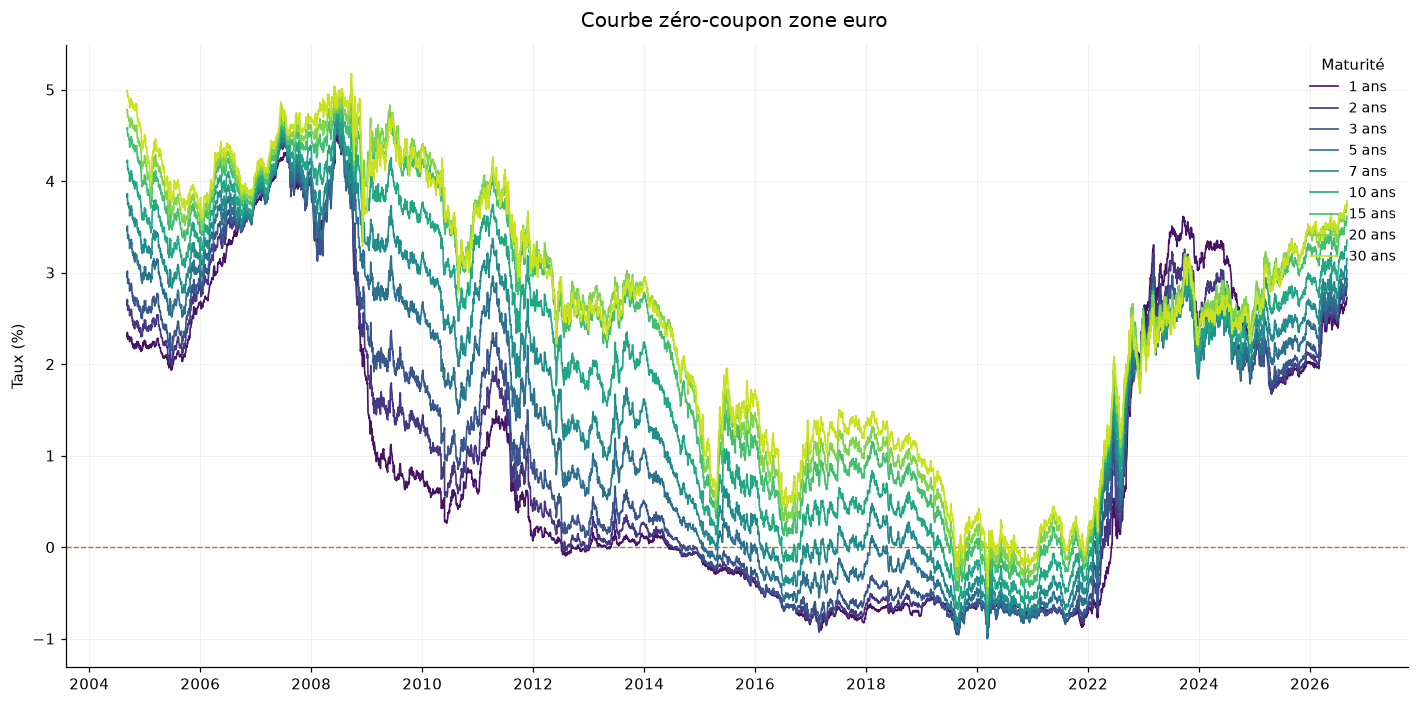

In [14]:
fig, ax = plt.subplots()

couleurs = plt.cm.viridis(np.linspace(0.05, 0.92, len(courbe.columns)))

for coul, mat in zip(couleurs, courbe.columns):
    ax.plot(courbe.index, courbe[mat], color=coul, lw=1.1, label=f"{mat} ans")

ax.axhline(0, color="#B5651D", lw=0.9, ls="--", zorder=1)
ax.set_title("Courbe zéro-coupon zone euro ", fontsize=13, pad=12)
ax.set_ylabel("Taux (%)")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(ncol=1, loc="upper right", frameon=False, fontsize=9, title="Maturité")

fig.tight_layout()
plt.show()

### Lecture

Trois régimes se distinguent, et ce sont eux qui comptent pour un modèle ALM.

1. **Avant 2008** niveau élevé, courbe plate voire inversée par moments.
2. **2015-2021** taux courts nettement négatifs.
3. **Depuis 2022**  remontée brutale, inversion de la courbe en 2023, puis
   repentification.

## 3. Historique long sur le 10 ans

Pour couvrir 2000-2004, que la courbe zéro-coupon ne remonte pas.

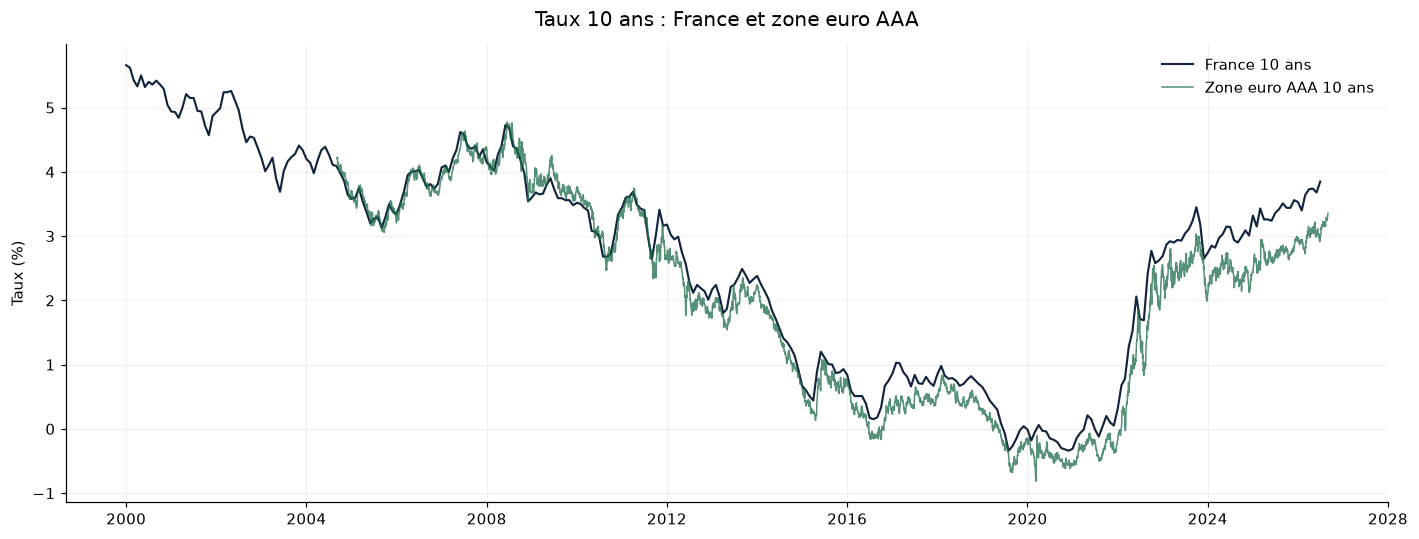

In [15]:
fr10 = charger_serie("IRS/M.FR.L.L40.CI.0000.EUR.N.Z", "fr_10a")
fr = fr10[fr10.index >= "2000-01-01"]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(fr.index, fr.values, color="#12233D", lw=1.4, label="France 10 ans")

ax.plot(courbe.index, courbe[10], color="#1C6B4A", lw=1.0, alpha=0.75,
                label="Zone euro AAA 10 ans")
ax.set_title("Taux 10 ans : France et zone euro AAA", fontsize=13, pad=12)
ax.set_ylabel("Taux (%)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()